<a href="https://colab.research.google.com/github/annjerinsundar-code/ICTAK-AI-ML-Coursework/blob/main/Supervised_Learning_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Understand and Explore the Dataset

###1.1 Load the dataset and inspect its structure.

In [141]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox

In [142]:
# Load the dataset
df = pd.read_csv('/content/bank-additional-full.csv')

# Display first 5 records
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [143]:
# No. of rows and columns
df.shape

(41188, 21)

In [144]:
# Column names
df.columns.to_list()

['age',
 'job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'y']

In [145]:
# Check data types and null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [146]:
# Statistical summary of the data
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [147]:
# Check for missing values
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [148]:
# Check for duplicate records
duplicate_count = df.duplicated().sum()
print("Number of duplicate records: ",duplicate_count)

Number of duplicate records:  12


###1.2 Identify numerical and categorical features.

In [149]:
# Numerical features
numerical_features = df.select_dtypes(include='number').columns.tolist()

# Categorical features
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

#Remove target variable from categorical features
categorical_features.remove('y')

print("Numerical features: ",numerical_features)
print("Categorical features: ",categorical_features)

Numerical features:  ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features:  ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### 1.3 Analyze the distribution of the target variable y.

In [150]:
# Count the occurences of each target class ['Yes' and 'No']
df['y'].value_counts()

,count
y,
no,36548
yes,4640


In [151]:
# Calculate the percentage distribution
df['y'].value_counts(normalize=True)*100

,proportion
y,
no,88.734583
yes,11.265417


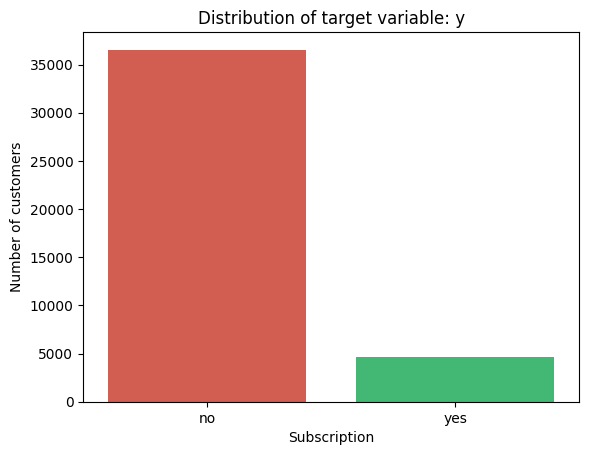

In [152]:
# Visualize target distribution
color_dict = {'yes':'#2ecc71', 'no':'#e74c3c'} # For custom hues for each class
sns.countplot(x='y',data=df, hue='y', palette=color_dict)
plt.title('Distribution of target variable: y')
plt.xlabel('Subscription')
plt.ylabel('Number of customers')
plt.show()

#2. Data Preprocessing

###2.1 Handle missing or unknown values using suitable techniques.

In [153]:
# Check for missing values in each column
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [154]:
# Check for total number of missing values
print("Total number of missing values: ",df.isnull().sum().sum())

Total number of missing values:  0


In [155]:
# Identify unknown values
'''This dataset uses the word unknown in some categorical columns. These are not actual null values, so isnull() will not detect them.'''

# Count unknown values in categorical columns
for column in categorical_features:
  unknown_count = (df[column] == 'unknown').sum()
  print(f"{column}: {unknown_count}")

job: 330
marital: 80
education: 1731
default: 8597
housing: 990
loan: 990
contact: 0
month: 0
day_of_week: 0
poutcome: 0


In [156]:
# Retaining unknown as a separate category

In [157]:
# Remove duplicate records
df_processed = df.copy() # Create copy of original dataset
df_processed = df_processed.drop_duplicates()
print("Previous dataframe shape: ",df.shape)
print("Processed dataframe shape: ",df_processed.shape)

Previous dataframe shape:  (41188, 21)
Processed dataframe shape:  (41176, 21)


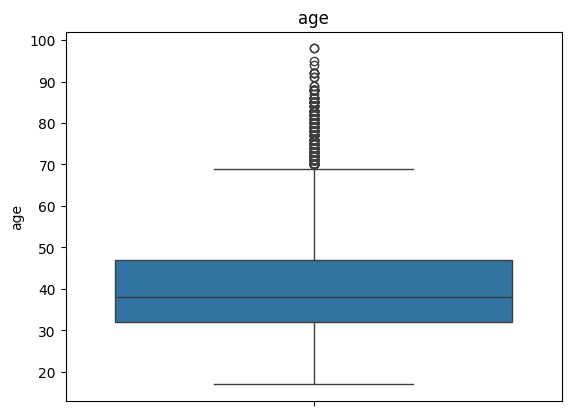

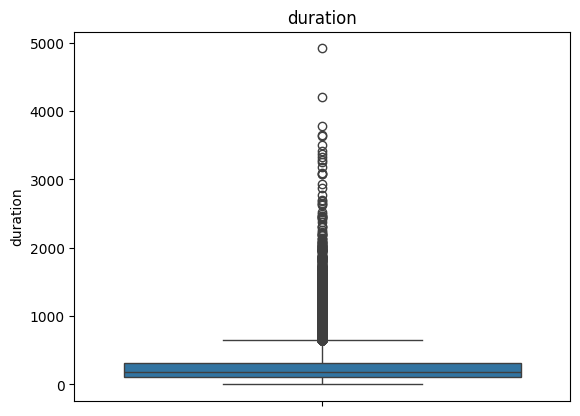

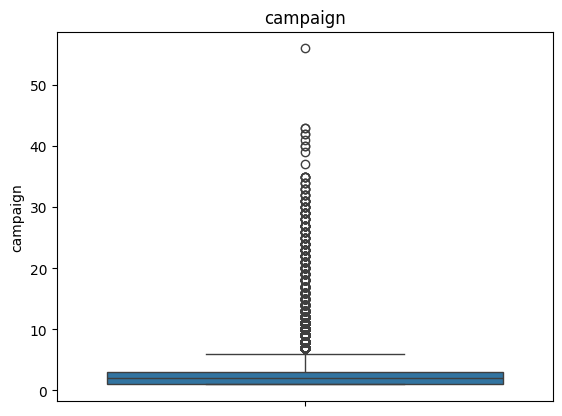

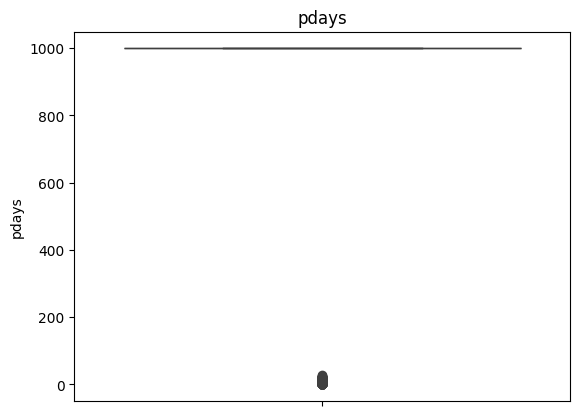

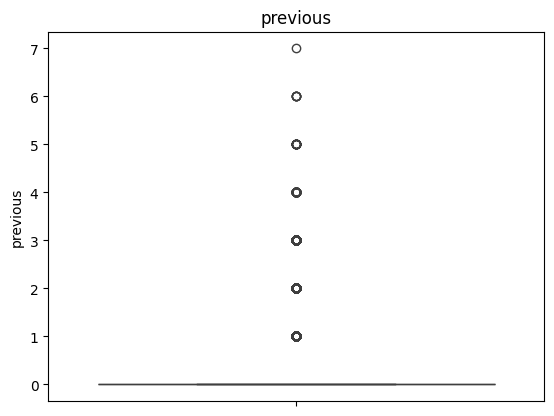

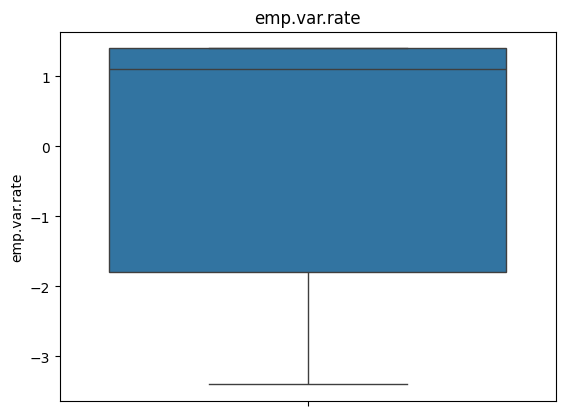

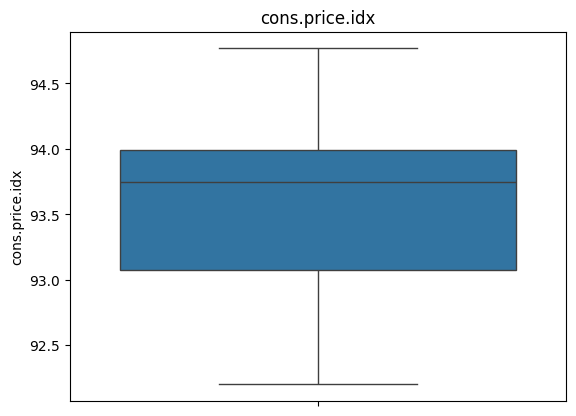

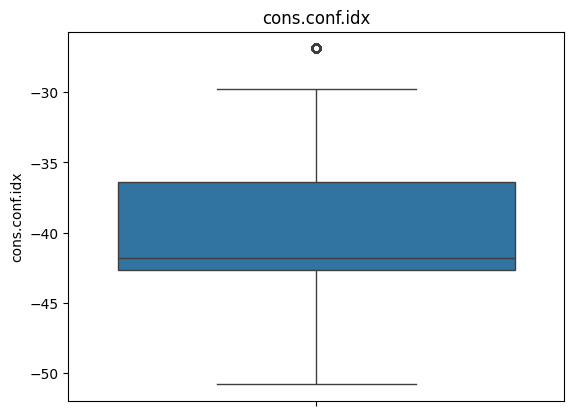

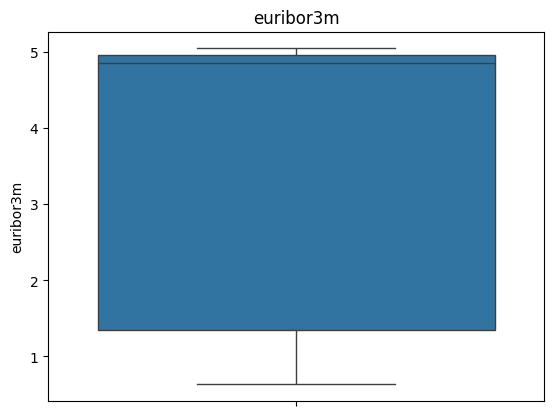

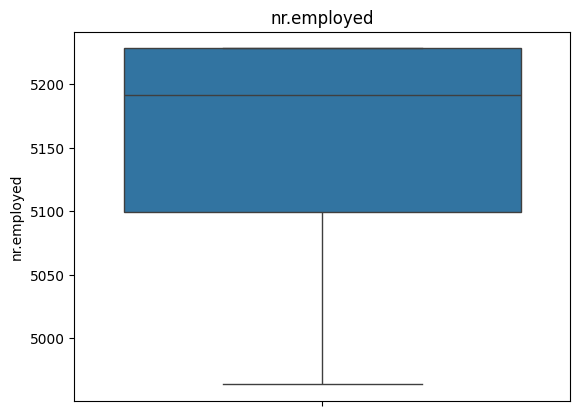

In [158]:
# Visualize outliers using boxplots
for i in numerical_features:
  sns.boxplot(df_processed[i])
  plt.title(i)
  plt.show()

In [159]:
# Detect outliers using IQR method
outlier_summary = []

for column in numerical_features:
    Q1 = df_processed[column].quantile(0.25)
    Q3 = df_processed[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df_processed[
        (df_processed[column] < lower_limit) |
        (df_processed[column] > upper_limit)
    ]

    outlier_summary.append({
        'Feature': column,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Feature,Lower Limit,Upper Limit,Outlier Count
0,age,9.5000,69.5000,468
1,duration,-223.5000,644.5000,2963
2,campaign,-2.0000,6.0000,2406
3,pdays,999.0000,999.0000,1515
4,previous,0.0000,0.0000,5625
5,emp.var.rate,-6.6000,6.2000,0
6,cons.price.idx,91.6965,95.3725,0
7,cons.conf.idx,-52.1500,-26.9500,446
8,euribor3m,-4.0815,10.3865,0
9,nr.employed,4905.6000,5421.6000,0


The IQR method identified potential outliers in six numerical features: age, duration, campaign, pdays, previous, and cons.conf.idx. However, further investigation suggests that many of these values represent genuine customer behaviour or special dataset encodings rather than errors. In particular, the value 999 in pdays indicates that a customer was not previously contacted. Therefore, no outlier records were removed at this stage.

In [160]:
# Calculate skewness
skewness = df_processed[numerical_features].skew()
skewness.sort_values(ascending=False)

,0
campaign,4.762044
previous,3.831396
duration,3.262808
age,0.784560
cons.conf.idx,0.302876
cons.price.idx,-0.230853
euribor3m,-0.709194
emp.var.rate,-0.724061
nr.employed,-1.044317
pdays,-4.921386


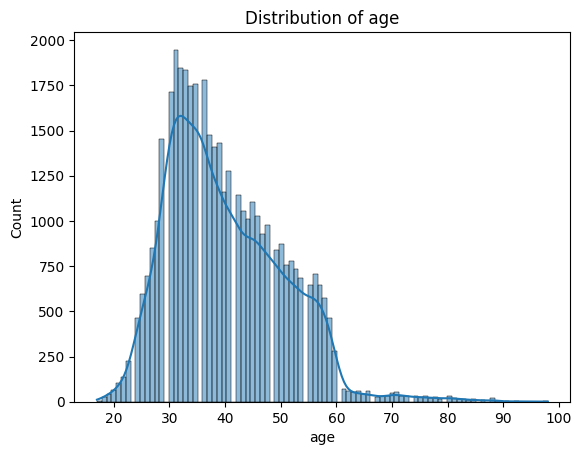

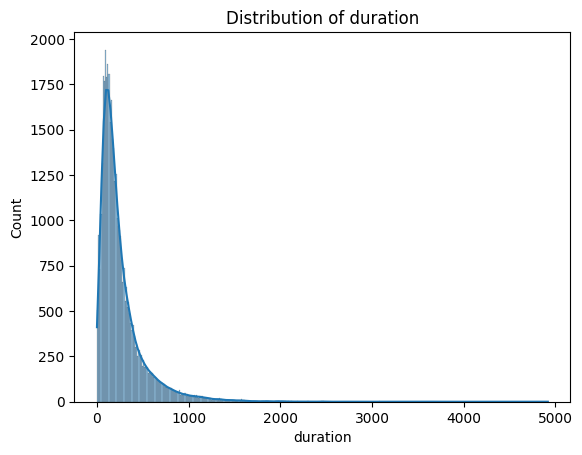

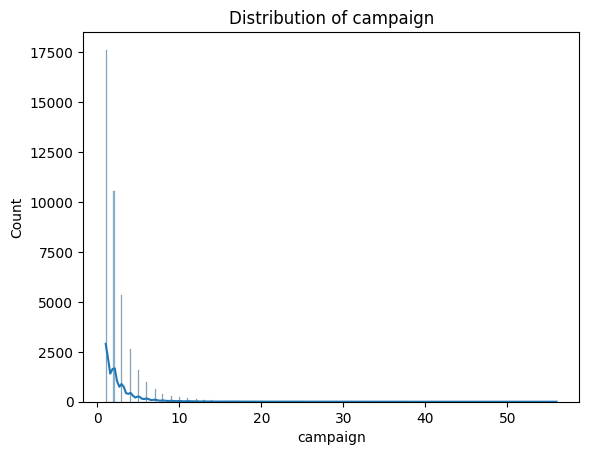

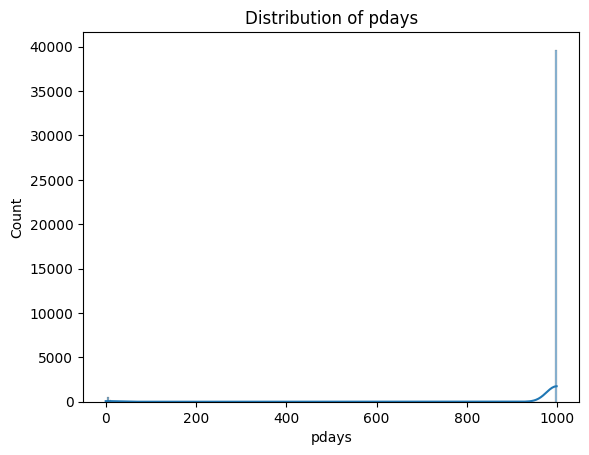

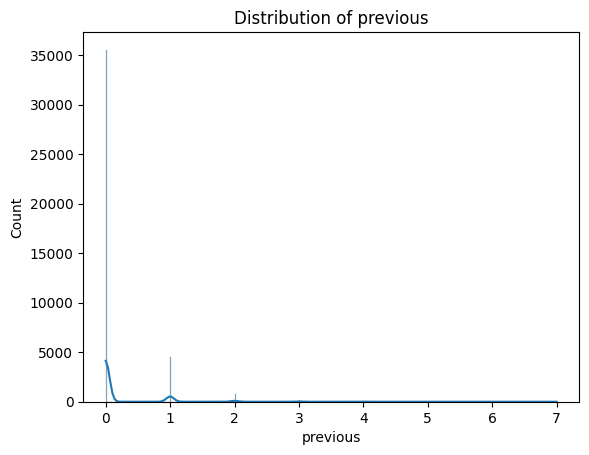

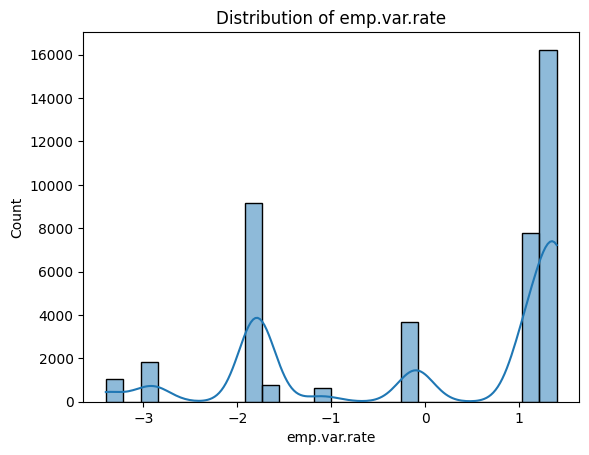

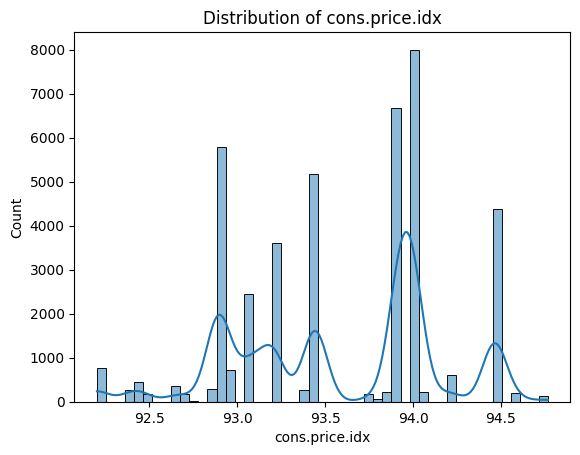

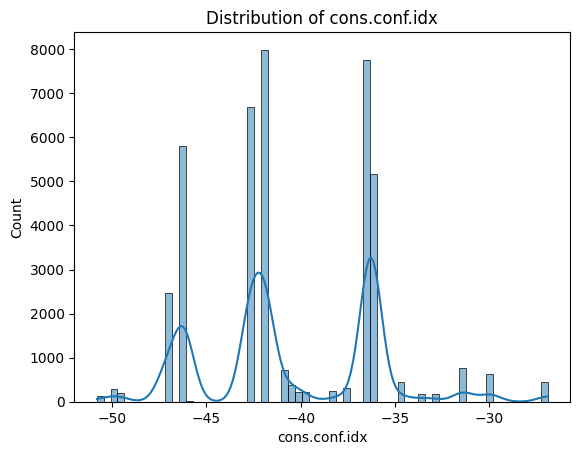

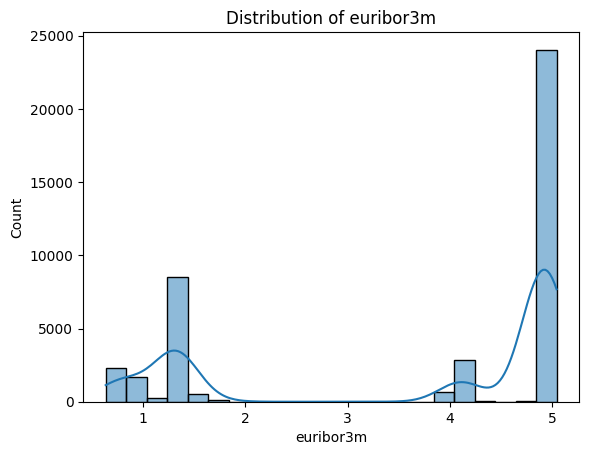

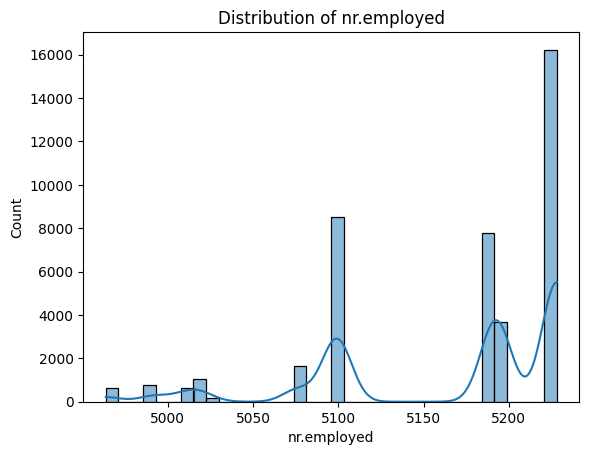

In [161]:
# Visualize the distributions
for i in numerical_features:
  sns.histplot(df_processed[i], kde=True)
  plt.title(f'Distribution of {i}')
  plt.show()

In [162]:
# Skewness transformation
df_transformed = df_processed.copy()

# Duration
# Cube Root Transformation
df_transformed['duration_cbrt'] = np.cbrt(df_transformed['duration'])

# Box-Cox Transformation
df_transformed['duration_boxcox'], duration_lambda = boxcox(
    df_transformed['duration'] + 1
)

# Duration
print("DURATION")

# Compare skewness
print("Original Skewness:", df_transformed['duration'].skew())
print("Cube Root Skewness:", df_transformed['duration_cbrt'].skew())
print("Box-Cox Skewness:", df_transformed['duration_boxcox'].skew())
print("Box-Cox Lambda:", duration_lambda)

# Campaign
print("\nCAMPAIGN")
# Cube Root Transformation
df_transformed['campaign_cbrt'] = np.cbrt(df_transformed['campaign'])

# Square Root Transformation
df_transformed['campaign_sqrt'] = np.sqrt(df_transformed['campaign'])

# Log Transformation
df_transformed['campaign_log'] = np.log1p(df_transformed['campaign'])

# Compare skewness
print("Original Skewness:", df_transformed['campaign'].skew())
print("Cube Root Skewness:", df_transformed['campaign_cbrt'].skew())
print("Square Root Skewness:", df_transformed['campaign_sqrt'].skew())
print("Log Skewness:", df_transformed['campaign_log'].skew())

# Previous
print("\nPREVIOUS")
# Cube Root Transformation
df_transformed['previous_cbrt'] = np.cbrt(df_transformed['previous'])

# Compare skewness
print("Original Skewness:", df_transformed['previous'].skew())
print("Cube Root Skewness:", df_transformed['previous_cbrt'].skew())

# Euribor3m
print("\nEURIBOR3M")
# Cube Root Transformation
df_transformed['euribor3m_cbrt'] = np.cbrt(df_transformed['euribor3m'])
# Compare skewness
print("Original Skewness:", df_transformed['euribor3m'].skew())
print("Cube Root Skewness:", df_transformed['euribor3m_cbrt'].skew())



DURATION
Original Skewness: 3.262807509494723
Cube Root Skewness: 0.6647171311990094
Box-Cox Skewness: 0.016944380058222245
Box-Cox Lambda: 0.12514234441393132

CAMPAIGN
Original Skewness: 4.76204406111779
Cube Root Skewness: 1.6426503778400219
Square Root Skewness: 2.1684171532735426
Log Skewness: 1.3502653832482818

PREVIOUS
Original Skewness: 3.831395514122408
Cube Root Skewness: 2.216841144480779

EURIBOR3M
Original Skewness: -0.7091942125590558
Cube Root Skewness: -0.7942874628098027


###2.2 Split the dataset into training and testing sets.

In [163]:
# Separate independent and dependent variables
X = df_processed.drop(columns='y')
y = df_processed['y']

# Encode the target variable
y = y.map({'no': 0, 'yes': 1})

# Check target encoding
print("Target variable distribution:")
print(y.value_counts())

Target variable distribution:
y
0    36537
1     4639
Name: count, dtype: int64


In [164]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (32940, 20)
X_test: (8236, 20)
y_train: (32940,)
y_test: (8236,)


###2.3 Encode categorical variables using appropriate encoding methods.

In [165]:
# Categorical columns without target column
categorical_features = X.select_dtypes(include=['object']).columns.tolist()
X_train_categorical = X_train[categorical_features]
X_train_categorical.head()

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome
36454,technician,single,professional.course,no,no,no,cellular,jun,tue,failure
1233,blue-collar,married,professional.course,no,no,no,telephone,may,thu,nonexistent
24111,self-employed,single,university.degree,no,no,no,telephone,nov,thu,nonexistent
15516,entrepreneur,married,basic.9y,no,no,yes,telephone,jul,fri,nonexistent
17916,services,married,high.school,no,yes,yes,cellular,jul,tue,nonexistent


In [200]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)


In [167]:
# analyzing number of categories in each column
for col in categorical_features:
    print(col, ":", X_categorical[col].nunique())

job : 12
marital : 4
education : 8
default : 3
housing : 3
loan : 3
contact : 2
month : 10
day_of_week : 5
poutcome : 3


In [168]:
sum(X_categorical[col].nunique() for col in categorical_features)

53

In [169]:
# Fit the encoder and transform training data
X_train_encoded = encoder.fit_transform(X_train_categorical)
X_train_encoded.shape

(32940, 53)

In [170]:
# Select categorical columns from test data
X_test_categorical = X_test[categorical_features]

# Transform test data
X_test_encoded = encoder.transform(X_test_categorical)
X_test_encoded.shape

(8236, 53)

In [171]:
# Identify numerical features
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(numerical_features)
print("Number of numerical features:", len(numerical_features))

['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Number of numerical features: 10


In [172]:
# Select numerical columns from training data
X_train_numerical = X_train[numerical_features]

# Select numerical columns from testing data
X_test_numerical = X_test[numerical_features]

print("Training numerical data:", X_train_numerical.shape)
print("Testing numerical data:", X_test_numerical.shape)

Training numerical data: (32940, 10)
Testing numerical data: (8236, 10)


###2.4 Scale numerical features where required.

In [173]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [174]:
# Fit the scaler on training data and scale it
X_train_scaled = scaler.fit_transform(X_train_numerical)

# Use the same scaler to transform testing data
X_test_scaled = scaler.transform(X_test_numerical)

# Convert the scaled arrays back into DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=numerical_features,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=numerical_features,
    index=X_test.index
)

# Display output head
print(X_train_scaled.head())

# Display the shapes
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

            age  duration  campaign     pdays  previous  emp.var.rate  \
36454 -1.532272 -0.527170 -0.202879  0.195027  1.657135     -1.896387   
1233  -0.766955  3.344770 -0.563899  0.195027 -0.348598      0.648985   
24111 -0.671290 -0.348525 -0.563899  0.195027 -0.348598     -0.114627   
15516 -0.192967 -0.499985  0.519161  0.195027 -0.348598      0.839888   
17916 -0.097303 -0.235901  0.519161  0.195027 -0.348598      0.839888   

       cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
36454       -1.057203      -0.062687  -1.357248    -1.252900  
1233         0.722038       0.887842   0.712567     0.332805  
24111       -0.648202      -0.321922   0.361165     0.399107  
15516        0.590881      -0.473142   0.771326     0.845259  
17916        0.590881      -0.473142   0.773630     0.845259  
Scaled training data: (32940, 10)
Scaled testing data: (8236, 10)


#3. Apply Classification Models

In [175]:
# Combine scaled numerical and encoded categorical features
X_train_final = pd.concat(
    [
        X_train_scaled,
        pd.DataFrame(
            X_train_encoded,
            columns=encoder.get_feature_names_out(categorical_features),
            index=X_train.index
        )
    ],
    axis=1
)

X_test_final = pd.concat(
    [
        X_test_scaled,
        pd.DataFrame(
            X_test_encoded,
            columns=encoder.get_feature_names_out(categorical_features),
            index=X_test.index
        )
    ],
    axis=1
)

# Check the dimensions
print("Final training data:", X_train_final.shape)
print("Final testing data:", X_test_final.shape)

Final training data: (32940, 63)
Final testing data: (8236, 63)


In [176]:
# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

In [177]:
# Initialize the models
logistic_model = LogisticRegression(max_iter=1000)
knn_model = KNeighborsClassifier(n_neighbors=5)
svm_model = LinearSVC(random_state=42, max_iter=5000)
decision_tree_model = DecisionTreeClassifier(random_state=42)

In [178]:
# Train Logistic Regression
logistic_model.fit(X_train_final, y_train)

# Train KNN
knn_model.fit(X_train_final, y_train)

# Train SVM
svm_model.fit(X_train_final, y_train)

# Train Decision Tree
decision_tree_model.fit(X_train_final, y_train)

print("All four classification models have been trained successfully.")

All four classification models have been trained successfully.


In [179]:
# Predictions using each model
y_pred_logistic = logistic_model.predict(X_test_final)

y_pred_knn = knn_model.predict(X_test_final)

y_pred_svm = svm_model.predict(X_test_final)

y_pred_tree = decision_tree_model.predict(X_test_final)

In [180]:
# Display the first 10 predictions from each model

print("Logistic Regression Predictions:")
print(y_pred_logistic[:10])

print("\nKNN Predictions:")
print(y_pred_knn[:10])

print("\nSVM Predictions:")
print(y_pred_svm[:10])

print("\nDecision Tree Predictions:")
print(y_pred_tree[:10])

Logistic Regression Predictions:
[0 1 0 0 0 0 0 0 0 0]

KNN Predictions:
[0 1 0 0 0 0 0 0 0 0]

SVM Predictions:
[0 1 0 0 0 0 0 0 0 0]

Decision Tree Predictions:
[0 1 0 0 0 0 0 0 0 0]


In [181]:
# Compare actual and predicted values
prediction_comparison = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Logistic Regression': y_pred_logistic[:10],
    'KNN': y_pred_knn[:10],
    'SVM': y_pred_svm[:10],
    'Decision Tree': y_pred_tree[:10]
})

prediction_comparison

,Actual,Logistic Regression,KNN,SVM,Decision Tree
0,0,0,0,0,0
1,1,1,1,1,1
2,0,0,0,0,0
3,0,0,0,0,0
4,0,0,0,0,0
5,0,0,0,0,0
6,0,0,0,0,0
7,0,0,0,0,0
8,0,0,0,0,0
9,0,0,0,0,0


#4. Apply Ensemble Learning Methods

In [182]:
# Import ensemble algorithms
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.tree import DecisionTreeClassifier

In [183]:
# Initialize ensemble models
''' n-estimators = No. of trees or weak learners used
    random_state=42 = Ensures reproducible results
    n_jobs=-1 =  Uses all available CPU cores'''

# Initialize Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Initialize Bagging Classifier
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

# Initialize AdaBoost Classifier
adaboost_model = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

# Initialize Gradient Boosting Classifier
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

In [184]:
# Train ensemble models

# Train Random Forest
random_forest_model.fit(X_train_final, y_train)

# Train Bagging Classifier
bagging_model.fit(X_train_final, y_train)

# Train AdaBoost
adaboost_model.fit(X_train_final, y_train)

# Train Gradient Boosting
gradient_boosting_model.fit(X_train_final, y_train)

print("All ensemble models have been trained successfully.")

All ensemble models have been trained successfully.


In [185]:
# Generate predictions using each model
y_pred_rf = random_forest_model.predict(X_test_final)

y_pred_bagging = bagging_model.predict(X_test_final)

y_pred_adaboost = adaboost_model.predict(X_test_final)

y_pred_gb = gradient_boosting_model.predict(X_test_final)

In [186]:
# Display predictions from each ensemble model
print("Random Forest Predictions:")
print(y_pred_rf[:10])

print("\nBagging Classifier Predictions:")
print(y_pred_bagging[:10])

print("\nAdaBoost Predictions:")
print(y_pred_adaboost[:10])

print("\nGradient Boosting Predictions:")
print(y_pred_gb[:10])

Random Forest Predictions:
[0 1 0 0 0 0 0 0 0 0]

Bagging Classifier Predictions:
[0 1 0 0 0 0 0 0 0 0]

AdaBoost Predictions:
[0 1 0 0 0 0 0 0 0 0]

Gradient Boosting Predictions:
[0 1 0 0 0 0 0 0 0 0]


In [187]:
# Compare actual and predicted values
ensemble_prediction_comparison = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Random Forest': y_pred_rf[:10],
    'Bagging': y_pred_bagging[:10],
    'AdaBoost': y_pred_adaboost[:10],
    'Gradient Boosting': y_pred_gb[:10]
})

ensemble_prediction_comparison

,Actual,Random Forest,Bagging,AdaBoost,Gradient Boosting
0,0,0,0,0,0
1,1,1,1,1,1
2,0,0,0,0,0
3,0,0,0,0,0
4,0,0,0,0,0
5,0,0,0,0,0
6,0,0,0,0,0
7,0,0,0,0,0
8,0,0,0,0,0
9,0,0,0,0,0


#5. Model Evaluation

In [188]:
# Import evaluation metrics functions
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [189]:
# Collect predictions from all 8 models
model_predictions = {
    'Logistic Regression': y_pred_logistic,
    'KNN': y_pred_knn,
    'SVM': y_pred_svm,
    'Decision Tree': y_pred_tree,
    'Random Forest': y_pred_rf,
    'Bagging': y_pred_bagging,
    'AdaBoost': y_pred_adaboost,
    'Gradient Boosting': y_pred_gb
}

In [190]:
# Calculate evaluation metrics for all models
results = []

for model_name, predictions in model_predictions.items():
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1
    })

evaluation_results = pd.DataFrame(results)
evaluation_results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.909543,0.652246,0.422414,0.512753
1,KNN,0.901408,0.585799,0.426724,0.493766
2,SVM,0.910029,0.682975,0.376078,0.485059
3,Decision Tree,0.890238,0.512987,0.510776,0.511879
4,Random Forest,0.914036,0.670279,0.466595,0.550191
5,Bagging,0.913065,0.631188,0.549569,0.587558
6,AdaBoost,0.903473,0.600302,0.428879,0.500314
7,Gradient Boosting,0.916586,0.654685,0.549569,0.597540


In [191]:
# Compare model performance
evaluation_results_sorted = evaluation_results.sort_values(
    by='F1-score',
    ascending=False
)

evaluation_results_sorted

,Model,Accuracy,Precision,Recall,F1-score
7,Gradient Boosting,0.916586,0.654685,0.549569,0.597540
5,Bagging,0.913065,0.631188,0.549569,0.587558
4,Random Forest,0.914036,0.670279,0.466595,0.550191
0,Logistic Regression,0.909543,0.652246,0.422414,0.512753
3,Decision Tree,0.890238,0.512987,0.510776,0.511879
6,AdaBoost,0.903473,0.600302,0.428879,0.500314
1,KNN,0.901408,0.585799,0.426724,0.493766
2,SVM,0.910029,0.682975,0.376078,0.485059


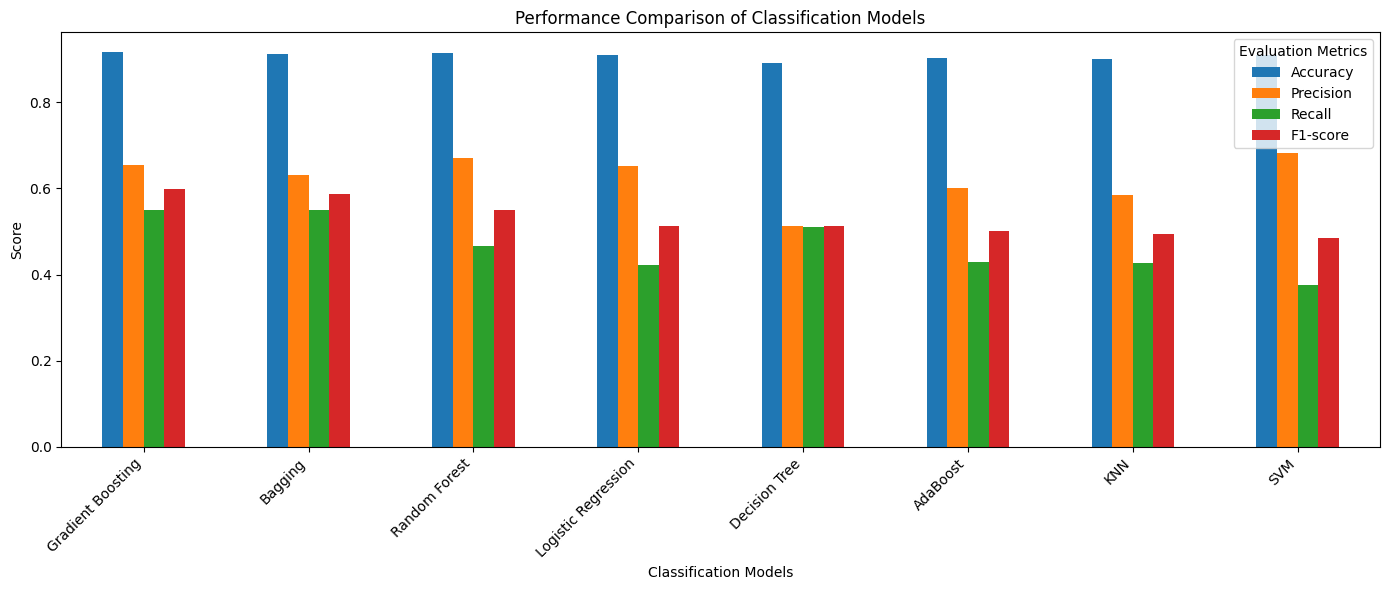

In [192]:
# Visualize performance of all models
evaluation_results_sorted.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1-score']
].plot(kind='bar', figsize=(14, 6))

plt.title('Performance Comparison of Classification Models')
plt.xlabel('Classification Models')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

In [193]:
# Compare individual models vs Ensemble models
individual_models = [
    'Logistic Regression',
    'KNN',
    'SVM',
    'Decision Tree'
]

ensemble_models = [
    'Random Forest',
    'Bagging',
    'AdaBoost',
    'Gradient Boosting'
]

evaluation_results['Model Type'] = evaluation_results['Model'].apply(
    lambda x: 'Individual' if x in individual_models else 'Ensemble'
)

group_comparison = evaluation_results.groupby('Model Type')[
    ['Accuracy', 'Precision', 'Recall', 'F1-score']
].mean()

group_comparison

,Accuracy,Precision,Recall,F1-score
Model Type,,,,
Ensemble,0.911790,0.639113,0.498653,0.558901
Individual,0.902805,0.608502,0.433998,0.500864


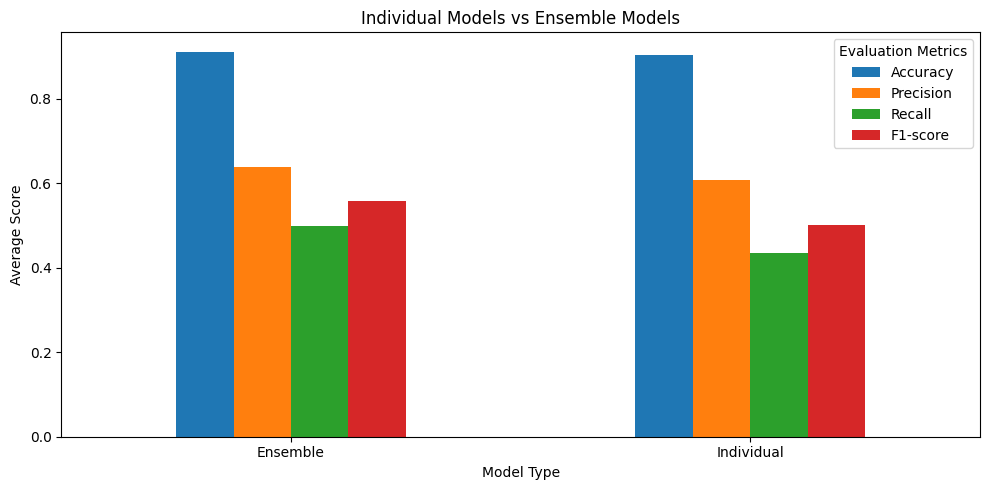

In [194]:
# Visualize Individual vs Ensemble Models
group_comparison.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Individual Models vs Ensemble Models')
plt.xlabel('Model Type')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

#6. Model Selection and Interpretation

###6.1 Identify the best-performing model.

In [195]:
# Identify best performing model
best_model = evaluation_results.loc[evaluation_results['F1-score'].idxmax()]

print("Best Performing Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1-score:", round(best_model['F1-score'], 4))

Best Performing Model: Gradient Boosting
Accuracy: 0.9166
Precision: 0.6547
Recall: 0.5496
F1-score: 0.5975


###6.2 Justification based on evaluation metrics.

The best-performing model **'Gradient Boosting'** was selected based on its F1-score, which considers both precision and recall. Accuracy, precision, recall and F1-score were also examined to obtain a more comprehensive understanding of the model's performance. Since the dataset contains more customers who did not subscribe than customers who subscribed, accuracy alone may not provide a reliable indication of model performance.

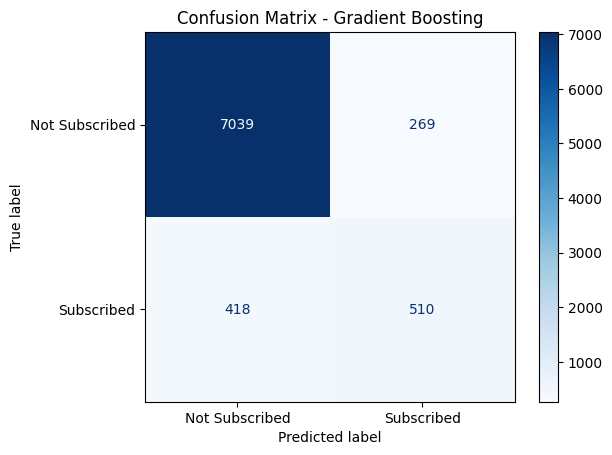

In [196]:
# Confusion Matrix for the best performing model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Get predictions from the best model
best_predictions = model_predictions[best_model['Model']]

# Generate confusion matrix
cm = confusion_matrix(y_test, best_predictions)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Subscribed', 'Subscribed']
)

disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix - {best_model['Model']}")
plt.show()

###6.3 Which features influence customer subscription the most

In [197]:
# Create a dictionary of trained models
trained_models = {
    'Logistic Regression': logistic_model,
    'KNN': knn_model,
    'SVM': svm_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model,
    'Bagging': bagging_model,
    'AdaBoost': adaboost_model,
    'Gradient Boosting': gradient_boosting_model
}

best_model_object = trained_models[best_model['Model']]

In [198]:
# Calculate permutation importance
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model_object,
    X_test_final,
    y_test,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

              Feature  Importance
1            duration    0.307345
9         nr.employed    0.138110
8           euribor3m    0.021934
5        emp.var.rate    0.018858
7       cons.conf.idx    0.013386
3               pdays    0.009455
50          month_mar    0.008859
44  contact_telephone    0.008240
53          month_oct    0.007113
0                 age    0.007029
34         default_no    0.002532
62   poutcome_success    0.002140
2            campaign    0.001801
43   contact_cellular    0.001397
56    day_of_week_mon    0.001117


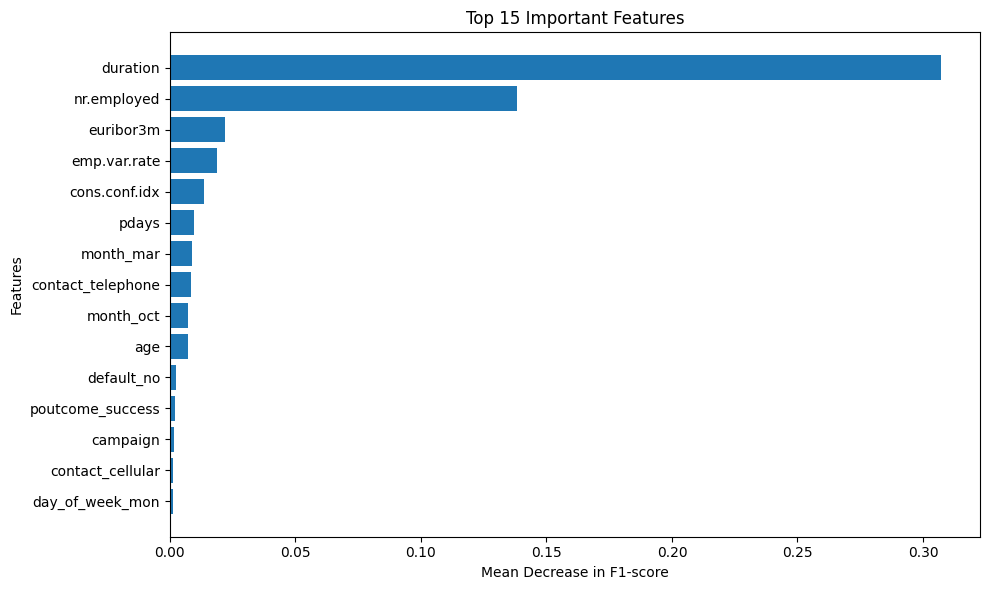

In [199]:
# Visualize top 15 features

feature_importance = pd.DataFrame({
    'Feature': X_test_final.columns,
    'Importance': importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
top_features = feature_importance.head(15)

print(top_features)

# Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.title('Top 15 Important Features')
plt.xlabel('Mean Decrease in F1-score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

Key observations
1. Duration (0.3073): This is the most influential feature. It has considerably greater importance than all other features. Longer call durations may be associated with a higher likelihood of subscription.

2. Number of employees (0.1381): nr.employed is the second most influential feature, suggesting that employment-related economic conditions contribute significantly to the model's predictions.

3. Economic indicators: euribor3m, emp.var.rate and cons.conf.idx also contribute to predictions. This suggests that economic conditions may be relevant to customer subscription behaviour.

4. Previous campaign information: pdays and poutcome_success contribute to the model's predictions, indicating that previous customer interactions may provide useful information.

5. Contact and timing: Features such as month_mar, month_oct and contact_telephone also influence predictions.

6. Other customer characteristics: Age, campaign frequency and default status have relatively lower permutation importance in this model.
---



The results indicate that **'duration'** is the most influential feature, with an
importance score of 0.3073.


---


Followed by **nr.employed** with 0.
1381. Economic indicators such as euribor3m, emp.var.rate and cons.conf.idx also contribute to the model's predictions.

Previous campaign information, including pdays and poutcome_success, along with contact method and the month of contact, also influence the predictions.

Overall, the findings suggest that call-related information, economic conditions and previous campaign outcomes play important roles in predicting customer subscription.

###6.4 Business insights on how the bank can improve marketing campaigns.

The marketing should emphasize:

1.   Using previous campaign outcomes to prioritize customers.
2.   Considering economic conditions when planning campaigns.
3. Evaluating suitable contact methods and campaign timing.
4. Avoiding excessive repeated contacts.
5. Using predictive models to allocate marketing resources efficiently.


